<a href="https://colab.research.google.com/github/rawanmd/segmentation_coverless_steg/blob/adaptive_window/Segmentation_Coverless_Steg_SAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from textwrap import indent
from google.colab import drive

import os
import glob
import json
import time
import math
import numpy as np

import torchvision
import torchvision.transforms.functional as F
import cv2
import matplotlib.pyplot as plt
import torch

In [2]:
INVERTED_INDEX_FILEPATH : str = "/content/drive/MyDrive/coco_dataset/sam_inverted_index.json"

## Connect to Drive

In [3]:
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

# Dataset root
dataset_dir = "/content/drive/MyDrive/coco_dataset"
os.makedirs(dataset_dir, exist_ok=True)

# Move into dataset folder
%cd $dataset_dir

# Create desired folders
os.makedirs("annotations", exist_ok=True)
os.makedirs("train", exist_ok=True)
os.makedirs("val", exist_ok=True)

# ==========================
# 1. ANNOTATIONS
# ==========================
# !wget -c http://images.cocodataset.org/annotations/annotations_trainval2017.zip

# !unzip -q annotations_trainval2017.zip
# !rm annotations_trainval2017.zip

# # ==========================
# # 2. VALIDATION IMAGES
# # ==========================
# !wget -c http://images.cocodataset.org/zips/val2017.zip

# !unzip -q val2017.zip
# !rm val2017.zip

# # Move images into val/
# !mv val2017/* val/
# !rmdir val2017

# ==========================
# 3. TRAIN IMAGES
# ==========================
# !wget -c http://images.cocodataset.org/zips/train2017.zip

# !unzip -q train2017.zip
# !rm train2017.zip

# # Move images into train/
# !mv train2017/* train/
# !rmdir train2017

Mounted at /content/drive
/content/drive/MyDrive/coco_dataset


## Import SAM

In [4]:
!pip install git+https://github.com/facebookresearch/segment-anything.git
!pip install opencv-python pycocotools matplotlib
!pip install torch torchvision

import torch
import cv2
import matplotlib.pyplot as plt

!wget https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-qhpsff3o
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-qhpsff3o
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36634 sha256=70782a5380dc2e37a3bde0f41c878e6500c4bd00bc7cf105ba9b5d743dee52a1
  Stored in directory: /tmp/pip-ephem-wheel-cache-465799dt/wheels/5d/7b/4a/c7fda89f2e27647dd0816f51ea103992b1b6f0f53ad234895c
Successfully built segment_anything
--2026-10-12 16:35:26--  https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 3.167.112.51, 3.167.112.53, 3.167.112.66, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|3.167.112

In [5]:
MODEL_TYPE = "vit_b"
CHECKPOINT = "sam_vit_b_01ec64.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(sam)

## Functions

In [6]:
def extract_masks(image_path):

  image = cv2.imread(image_path)
  image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  masks = mask_generator.generate(image)

  binary_seq = ""
  pix = 0

  for i in range(len(masks) - 1):
    bbox1 = masks[i]['bbox']
    x1, y1 = bbox1[:2]

    bbox2 = masks[i+1]['bbox']
    x2, y2 = bbox2[:2]

    d_squared = (x2 - x1)**2 + (y2 - y1)**2
    d = math.sqrt(d_squared)

    if(d <= 300):
      binary_seq += '0'
    else:
      binary_seq += '1'

  r, _, _ = cv2.split(image)
  pix = np.mean(r)

  return binary_seq, pix



def get_image_paths(dir):
  image_paths = sorted(glob.glob(os.path.join(dir, '*.jpg')))
  print(f"Found {len(image_paths)} images.")
  return image_paths



# def build_index(image_paths):
#   index = {}
#   image_paths = get_image_paths(image_paths)
#   print(f"image_paths: {image_paths}")
#   for image_path in image_paths:
#     # call segmentation model
#     binary_seq, pix = extract_masks(image_path)

#     if binary_seq is None or binary_seq == "":
#       continue

#     if binary_seq not in index:
#       index[binary_seq] = []

#     index[binary_seq].append({"image path": image_path,
#                               "pix": pix})

#     with open(str(dataset_dir)+"/inverted_index.json", "w") as f:
#       json.dump(index, f, indent=4)

#   return index

In [7]:
def build_index(image_dir):
  image_paths = get_image_paths(image_dir)

  if os.path.exists(INVERTED_INDEX_FILEPATH):
    print(f"Loading existing index from:\n{INVERTED_INDEX_FILEPATH}")

    with open(INVERTED_INDEX_FILEPATH, "r") as f:
      index = json.load(f)

    processed_images = set()

    for binary_seq, images in index.items():
      for image_info in images:
        processed_images.add(image_info["image path"])

    print(f"Already processed: {len(processed_images)} images")

  else:
    print("No existing index found. Starting from scratch.")
    index = {}
    processed_images = set()

  remaining_images = [
    image_path
    for image_path in image_paths
    if image_path not in processed_images
  ]

  print(f"Total images: {len(image_paths)}")
  print(f"Remaining images: {len(remaining_images)}")

  for count, image_path in enumerate(remaining_images, start=1):

    try:
      binary_seq, pix = extract_masks(image_path)

      if binary_seq is None or binary_seq == "":
        print(f"[{count}/{len(remaining_images)}] "
              f"Skipped: {image_path}")
        continue

      if binary_seq not in index:
        index[binary_seq] = []

      index[binary_seq].append({
        "image path": image_path,
        "pix": pix
      })

      temp_filepath = INVERTED_INDEX_FILEPATH + ".tmp"

      with open(temp_filepath, "w") as f:
        json.dump(index, f, indent=4)

      os.replace(temp_filepath, INVERTED_INDEX_FILEPATH)

      print(
        f"[{count}/{len(remaining_images)}] "
        f"Processed: {os.path.basename(image_path)} "
        f"| sequence length: {len(binary_seq)}"
      )

    except Exception as e:
      print(f"\nERROR processing: {image_path}")
      print(f"Error: {e}")
      print("Skipping this image and continuing...")
      continue

  processed_images = set()

  for binary_seq, images in index.items():
    for image_info in images:
      processed_images.add(image_info["image path"])

  print("\n==============================")
  print("Index building finished/stopped")
  print("==============================")
  print(f"Total dataset images: {len(image_paths)}")
  print(f"Images in index:      {len(processed_images)}")
  print(f"Remaining images:     {len(image_paths) - len(processed_images)}")
  print(f"Number of keys:       {len(index)}")

  return index

In [9]:
def match_msg_to_images(binary_msg: str, window_size: int, prefix_maps: dict) -> (list[str], int, int):
  """
  finds the optimal window size and matches images in the inverted index with the binary representation of the message.

  Searches using an index with variable-length keys.The scan window is sized to the longest key in the index, ensuring
  that all possible key matches can be detected.

  Args:
    binary_msg (str): Binary representation of the secret message.
    window_size (int): Maximum window size available in the inverted index.
    inverted_index (dict): contains all binary_sequences extracted from the images in the dataset and the images themselves.

  Returns:
    image_paths (list[str]): list of file paths of images that matched the binary message. Returns [] if matching failed.
    window_size (int): Final window size that successfully matched the entire message. Returns -1 if matching failed.
    num_zeros (int): the number of trailing zeroes that were added to the last chunk match the window size or -1 if matching failed.
  """

  for current_window_size in range(window_size, 0, -1):
    image_paths = []
    success = True
    pix_so_far = 0

    print(f"\nTrying window size: {current_window_size}")

    for i in range(0, len(binary_msg), current_window_size):

      chunk = binary_msg[i:i + current_window_size]
      num_zeros = 0

      # add trailing zeros to last chunk
      if len(chunk) < current_window_size:
          num_zeros = current_window_size - len(chunk)
          chunk = chunk.ljust(current_window_size, '0')

      print(f"chunk: {chunk}")

      keys = prefix_maps[current_window_size].get(chunk)

      if keys == None:
        print(f"No match for {chunk}")
        success = False
        break

      # valid_keys = [
      #   key for key in keys
      #   if key["pix"] > pix_so_far
      # ]

      # if not valid_keys:
      #     print(f"No valid image for {chunk} after pix {pix_so_far}")
      #     success = False
      #     break

      # key = min(valid_keys, key=lambda x: x["pix"])

      image_paths.append(keys[0]['image path'])
      # pix_so_far = key['pix']
      print(f"key: {keys[0]['image path']}")

    if success:
      print(f"\n\nimage paths: {image_paths}")
      print(f"Final window size: {current_window_size}")
      return image_paths, current_window_size, num_zeros

  return [], -1, -1



def build_prefix_maps(inverted_index):

  prefix_maps = {}

  for binary_seq, images in inverted_index.items():

      seq_len = len(binary_seq)

      for prefix_len in range(1, seq_len + 1):

          prefix = binary_seq[:prefix_len]

          if prefix_len not in prefix_maps:
              prefix_maps[prefix_len] = {}

          if prefix not in prefix_maps[prefix_len]:
              prefix_maps[prefix_len][prefix] = []

          prefix_maps[prefix_len][prefix].extend(images)

  return prefix_maps

In [10]:
def sort_pix(image_paths):
  res = []

  for path in image_paths:
    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    r, _, _ = cv2.split(image)

    pix = (int) (np.mean(r))

    res.append((path, pix))

  res.sort(key=lambda x: x[1])
  return [path for path, _ in res]



def extraxt_bin_msg(image_paths, window_size, num_zeros):
  bin_msg = ''
  image_paths = sort_pix(image_paths)

  for image_path in image_paths:
    # call segmentation model
    print("Hereeee")
    binary_seq, _ = extract_masks(image_path)

    if binary_seq is None:
      continue

    bin_msg += binary_seq[:window_size]

  if num_zeros > 0:
    num_zeros *= -1
    bin_msg[:num_zeros]

  return binary_msg

In [11]:
def string_to_binary(text: str) -> str:
    """
    Converts a string into a space-separated binary representation.
    """
    return ''.join(format(ord(char), '08b') for char in text)

def binary_to_string(binary_text: str) -> str:
    """
    Converts a space-separated binary string back into text.
    """
    return ''.join(
        chr(int(binary_text[i:i+8], 2))
        for i in range(0, len(binary_text), 8)
    )

## Embedding (Matching)

In [12]:
len(('helloworld'*1).encode('utf-8'))

10

In [14]:
start = time.perf_counter()

PATH = "/content/drive/MyDrive/coco_dataset/train2017"

secret_msg = "HelloWorld"

binary_msg = string_to_binary(secret_msg)

# build index if not already there
# inverted_index = build_index(PATH)

# load index if it exists
with open(INVERTED_INDEX_FILEPATH, "r") as f:
  inverted_index = json.load(f)

inverted_index = build_prefix_maps(inverted_index)

In [ ]:
window_size = max(inverted_index.keys())
print(f"Max window size in index: {window_size}")

images, w_size, num_zeros = match_msg_to_images(binary_msg, window_size, inverted_index)
# images, w_size, num_zeros = match_msg_to_images('1101111', 4, inverted_index)  # just an example for tracing

end = time.perf_counter()

Max window size in index: 371

Trying window size: 371
chunk: 01001000011001010110110001101100011011110101011101101111011100100110110001100100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
No match for 01001000011001010110110001101100011011110101011101101111011100100110110001100100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

Trying window size: 370
chunk: 01001000011001010110110001101100011011110101011101101111011100100110110001100100000000000000000000000000000000000000000000000000000000000000000000000

In [ ]:
print(f"Keys: {images}")
print(f"\nNumber of matches: {len(images)}")
print(f"\nWindow size: {w_size}")
print(f"\nNumber of zeroes added: {num_zeros}")

Keys: ['/content/drive/MyDrive/coco_dataset/train2017/000000017450.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000034478.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000035940.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000058174.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000232484.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000009791.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000015311.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000006764.jpg']

Number of matches: 8

Window size: 11

Number of zeroes added: 8


In [ ]:
print(f"Time taken for embedding: {end - start:.6f} seconds")

Time taken for embedding: 1.694762 seconds


## Extraction

In [ ]:
start = time.perf_counter()

extracted_bin_msg = extraxt_bin_msg(images, w_size, num_zeros)
extracted_bin_msg

Hereeee


KeyboardInterrupt: 

In [ ]:
extracted_msg = binary_to_string(extracted_bin_msg)

end = time.perf_counter()

extracted_msg

'Hello World'

In [ ]:
print(extracted_bin_msg == binary_msg)

print(f"Time taken for extraction: {end - start:.6f} seconds")

True
Time taken for extraction: 66.855718 seconds


## Testing

In [16]:
image_paths = get_image_paths(PATH)[0]
image_paths

Found 27633 images.


'/content/drive/MyDrive/coco_dataset/train2017/000000000034.jpg'

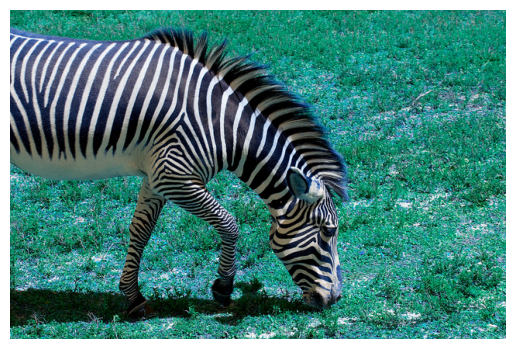

In [20]:
im = cv2.imread(image_paths)
plt.axis(False)
plt.imshow(im);

In [21]:
mask = extract_masks(image_paths)

In [24]:
mask[0]

'01000011011001011'

In [ ]:
/bin

In [31]:
cv2.imwrite("/test.jpg", im,
            [cv2.IMWRITE_JPEG_QUALITY, 90])

True

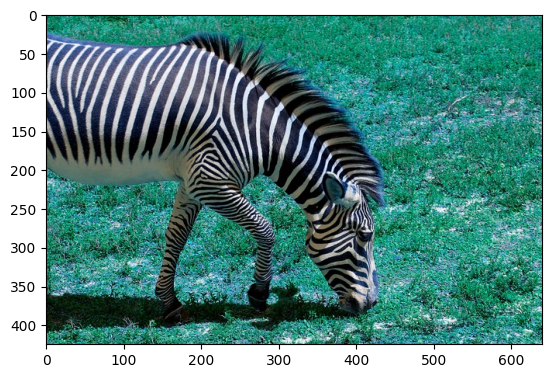

In [32]:
im2 = cv2.imread("/test.jpg")
plt.imshow(im2)

In [ ]:
mask2 = extract_masks("test.jpg")

In [ ]:
mask2